# 03 · Propensión de compra con LightGBM

**Pregunta de negocio:** ¿qué clientes van a volver a comprar en los próximos 14 días?
Con esa probabilidad, el dashboard ordena a quién contactar primero (probabilidad × ticket
= valor esperado) y explica el porqué de cada puntaje.

**Diseño temporal sin fuga.** Cada *snapshot* toma una fecha de corte *t*:

- las **features** usan solo compras hasta *t* (verificado en `tests/test_modelos.py`);
- la **etiqueta** es 1 si el hogar compra en (*t*, *t* + 14 días].

| Conjunto | Cortes | Uso |
|---|---|---|
| Entrenamiento | fin de mes, mar → oct 2017 (8 snapshots apilados) | ajustar modelos |
| Validación | 15-nov-2017 | elegir hiperparámetros, *early stopping* y calibración |
| Test | 1-dic-2017 | medir una sola vez, al final |
| Puntuación | 31-dic-2017 | lo que ve el dashboard (el futuro, sin etiqueta) |

Validar por tiempo, y no con un `train_test_split` aleatorio, reproduce cómo se usaría el
modelo: entrenado con el pasado y aplicado al futuro.

In [1]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve

from brujula_ml import features as F
from brujula_ml import graficos as G
from brujula_ml import propension as P
from brujula_ml.rutas import MODELOS, PROCESADOS

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:,.4f}".format)
G.estilo()

tx = F.transacciones()
c = F.cestas(tx)
camp = F.campanas()
X = F.FEATURES

ent = P.snapshots(c, P.CORTES_ENTRENAMIENTO, camp)
val = P.snapshot(c, P.CORTE_VALIDACION, camp)
test = P.snapshot(c, P.CORTE_TEST, camp)
pd.DataFrame(
    {
        "filas": [len(ent), len(val), len(test)],
        "tasa base (compran en 14 días)": [ent["y"].mean(), val["y"].mean(), test["y"].mean()],
    },
    index=["entrenamiento", "validación", "test"],
)

,filas,tasa base (compran en 14 días)
entrenamiento,19114,0.7227
validación,2458,0.7063
test,2463,0.7065


## 1. Variables

25 variables agrupadas en los **cinco factores** que muestra la app. Al final, los aportes
SHAP se suman por grupo para explicar cada puntaje en ese lenguaje.

In [2]:
pd.Series(F.GRUPOS, name="factor").rename_axis("variable").to_frame().groupby("factor").apply(
    lambda d: ", ".join(d.index)
).to_frame("variables")

,variables
factor,
frecuencia,"cestas_30, cestas_90, cestas_180, cestas_365, ..."
promos,"pct_descuento, pct_cestas_descuento, cupones_1..."
recencia,"recencia_dias, recencia_penultima, atraso_rela..."
tendencia,"tendencia_90, tendencia_30, pendiente_semanal"
valor,"gasto_30, gasto_90, gasto_180, gasto_365, tick..."


## 2. Línea base: regresión logística

Es lo que la demo simulaba hasta ahora: una combinación lineal de señales. Si el boosting
no la supera con claridad, no merece su complejidad.

In [3]:
logit = P.logistica().fit(ent[X], ent["y"])
p_logit = logit.predict_proba(test[X])[:, 1]

## 3. LightGBM con búsqueda bayesiana de hiperparámetros

Optuna (TPE) prueba 40 configuraciones y elige la de menor *log-loss* en validación; el
número de árboles lo fija el *early stopping* sobre ese mismo corte.

In [4]:
estudio = P.buscar_lgbm(ent[X], ent["y"], val[X], val["y"], intentos=40)
mejores = estudio.best_params | {"bagging_freq": 1}
rondas = estudio.best_trial.user_attrs["rondas"]
print(f"log-loss en validación: {estudio.best_value:.4f} · árboles: {rondas}")
pd.Series(mejores).to_frame("valor")

log-loss en validación: 0.4200 · árboles: 192


,valor
num_leaves,10.0000
min_data_in_leaf,28.0000
feature_fraction,0.8229
bagging_fraction,0.9050
lambda_l2,0.0088
bagging_freq,1.0000


In [5]:
modelo = P.entrenar_lgbm(ent[X], ent["y"], mejores, rondas=rondas)
z_val = P.log_odds(modelo, val[X])
z_test = P.log_odds(modelo, test[X])

## 4. Calibración

El dashboard muestra el puntaje como probabilidad ("de cada 10 clientes así, compran 8"),
así que tiene que estar **calibrado**. Se usa calibración de Platt (afín en *log-odds*),
ajustada en validación. Se eligió Platt y no isotónica porque, al ser afín, **conserva la
suma de los aportes SHAP**: el "por qué" de la app sigue cuadrando con el número.

Platt: a = 1.004, b = -0.077  (a≈1 y b≈0 ⇒ el modelo ya venía casi calibrado)


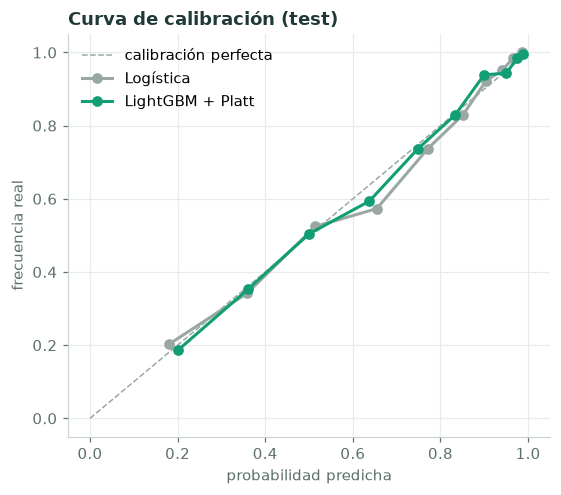

In [6]:
platt = P.Platt().fit(z_val, val["y"].to_numpy())
p_bruta = 1 / (1 + np.exp(-z_test))
p_lgbm = platt(z_test)
print(
    f"Platt: a = {platt.a:.3f}, b = {platt.b:+.3f}  (a≈1 y b≈0 ⇒ el modelo ya venía casi calibrado)"
)

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], color=G.BASE, ls="--", lw=1, label="calibración perfecta")
for p, nombre, color in [(p_logit, "Logística", G.BASE), (p_lgbm, "LightGBM + Platt", G.MARCA)]:
    real, pred = calibration_curve(test["y"], p, n_bins=10, strategy="quantile")
    ax.plot(pred, real, marker="o", color=color, lw=2, label=nombre)
ax.set(
    title="Curva de calibración (test)", xlabel="probabilidad predicha", ylabel="frecuencia real"
)
ax.legend()
fig.tight_layout()
G.guardar(fig, "03_calibracion")

## 5. Resultados en test

In [7]:
y_test = test["y"].to_numpy()
tabla = pd.DataFrame(
    {
        "Logística": P.metricas(y_test, p_logit),
        "LightGBM (sin calibrar)": P.metricas(y_test, p_bruta),
        "LightGBM + Platt": P.metricas(y_test, p_lgbm),
    }
).T
tabla

,roc_auc,pr_auc,brier,log_loss,tasa_base,precision_banda_alta,parte_banda_alta,lift_decil_1
Logística,0.8634,0.9406,0.1355,0.4135,0.7065,0.8611,0.6898,1.4155
LightGBM (sin calibrar),0.8668,0.9414,0.1332,0.4070,0.7065,0.8618,0.6935,1.4098
LightGBM + Platt,0.8668,0.9414,0.1329,0.4063,0.7065,0.8684,0.6788,1.4098


In [8]:
# ¿La ventaja de LightGBM es real o ruido? Bootstrap pareado sobre los hogares de test.
rng = np.random.default_rng(0)
dif = []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    dif.append(roc_auc_score(y_test[i], p_lgbm[i]) - roc_auc_score(y_test[i], p_logit[i]))
dif = np.array(dif)
print(
    f"Δ AUC (LightGBM − logística) = {dif.mean():+.4f}  ·  IC 95 % [{np.percentile(dif, 2.5):+.4f}, "
    f"{np.percentile(dif, 97.5):+.4f}]  ·  P(Δ > 0) = {(dif > 0).mean():.0%}"
)

Δ AUC (LightGBM − logística) = +0.0036  ·  IC 95 % [-0.0001, +0.0069]  ·  P(Δ > 0) = 97%


**Lectura honesta.** LightGBM gana en ranking y calibración, pero por poco (+0,004 de AUC), y la
diferencia está en el límite de lo significativo: el intervalo de confianza roza el cero. Una vez que el
modelo sabe *cuándo compró por última vez* el cliente y *con qué frecuencia viene*, queda poca
señal por exprimir, y una logística bien construida ya la captura casi toda (en el notebook
de exploración se ve por qué: el hábito domina la compra de supermercado). Aun así se elige
LightGBM para producción porque:

- todas las métricas apuntan en la misma dirección (AUC, PR-AUC, Brier, log-loss) y la
  calibración es mejor;
- captura no linealidades sin ingeniería manual (p. ej. el efecto de la recencia satura);
- TreeSHAP da explicaciones exactas por cliente, que es lo que ve el usuario en la app.

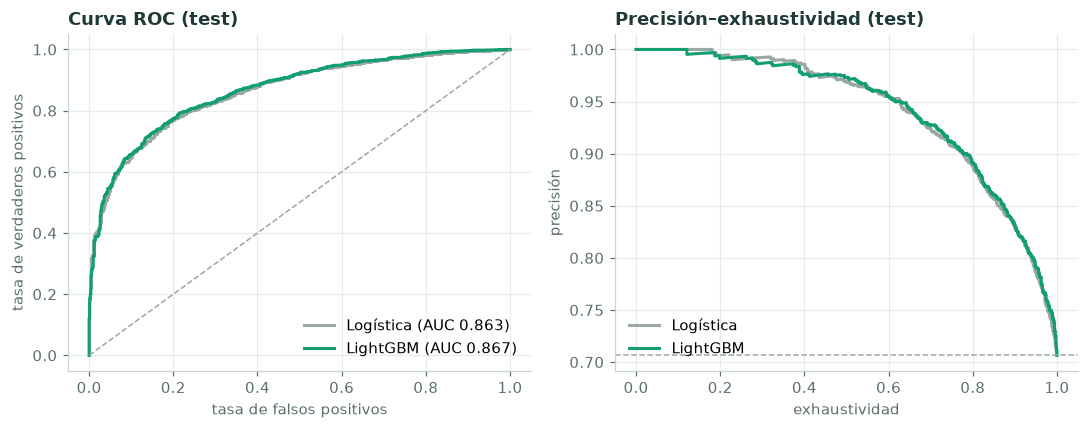

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
for p, nombre, color in [(p_logit, "Logística", G.BASE), (p_lgbm, "LightGBM", G.MARCA)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    a1.plot(fpr, tpr, color=color, lw=2, label=f"{nombre} (AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    a2.plot(rec, prec, color=color, lw=2, label=nombre)
a1.plot([0, 1], [0, 1], color=G.BASE, ls="--", lw=1)
a1.set(
    title="Curva ROC (test)",
    xlabel="tasa de falsos positivos",
    ylabel="tasa de verdaderos positivos",
)
a2.axhline(y_test.mean(), color=G.BASE, ls="--", lw=1)
a2.set(title="Precisión–exhaustividad (test)", xlabel="exhaustividad", ylabel="precisión")
a1.legend(loc="lower right")
a2.legend(loc="lower left")
fig.tight_layout()
G.guardar(fig, "03_roc_pr")

### ¿Sirve para priorizar? Lift por decil

Lo que importa al negocio: si contacto primero a quienes el modelo pone arriba, ¿acierto más
que al azar?

,clientes,compran,p_media,tasa,lift,captura_acumulada
decil,,,,,,
1,247,246,0.9874,0.9960,1.4098,0.1414
2,246,242,0.9746,0.9837,1.3925,0.2805
3,246,232,0.9502,0.9431,1.3350,0.4138
4,247,231,0.8996,0.9352,1.3238,0.5466
5,246,205,0.8333,0.8333,1.1796,0.6644
6,246,181,0.7484,0.7358,1.0415,0.7684
7,247,146,0.6372,0.5911,0.8367,0.8523
8,246,125,0.4993,0.5081,0.7193,0.9241
9,246,86,0.3606,0.3496,0.4949,0.9736


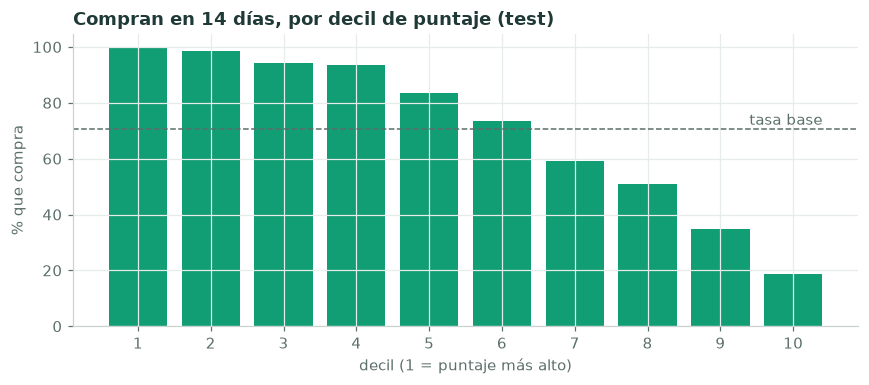

In [10]:
lift = P.lift_por_decil(y_test, p_lgbm)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(lift.index, lift["tasa"] * 100, color=G.MARCA)
ax.axhline(y_test.mean() * 100, color=G.TINTA_2, ls="--", lw=1)
ax.text(10.4, y_test.mean() * 100 + 1.5, "tasa base", color=G.TINTA_2, ha="right")
ax.set(
    title="Compran en 14 días, por decil de puntaje (test)",
    xlabel="decil (1 = puntaje más alto)",
    ylabel="% que compra",
)
ax.set_xticks(range(1, 11))
fig.tight_layout()
G.guardar(fig, "03_lift")
lift

El decil superior compra casi siempre, y el inferior menos de una vez de cada cinco. La
lectura más útil es por abajo: el 30 % de clientes con menor puntaje concentra a dos de cada
tres hogares que **no** volverán, que es donde una campaña de reactivación tiene sentido.

### Bandas de la app

El dashboard agrupa en bandas con los mismos cortes que usa hoy (`CORTE_ALTA = 60`,
`CORTE_MEDIA = 30` en `src/lib/data/propension.ts`).

In [11]:
banda = np.select([p_lgbm >= P.CORTE_ALTA, p_lgbm >= P.CORTE_MEDIA], ["alta", "media"], "baja")
pd.DataFrame({"banda": banda, "compra": y_test, "p": p_lgbm}).groupby("banda").agg(
    clientes=("compra", "size"), prob_media=("p", "mean"), compran_de_verdad=("compra", "mean")
).reindex(["alta", "media", "baja"])

,clientes,prob_media,compran_de_verdad
banda,,,
alta,1672,0.8703,0.8684
media,529,0.4496,0.4461
baja,262,0.2062,0.1985


En cada banda, la probabilidad que se promete coincide con lo que de verdad pasó: el
puntaje se puede leer literalmente.

## 6. ¿Por qué? Explicabilidad con SHAP

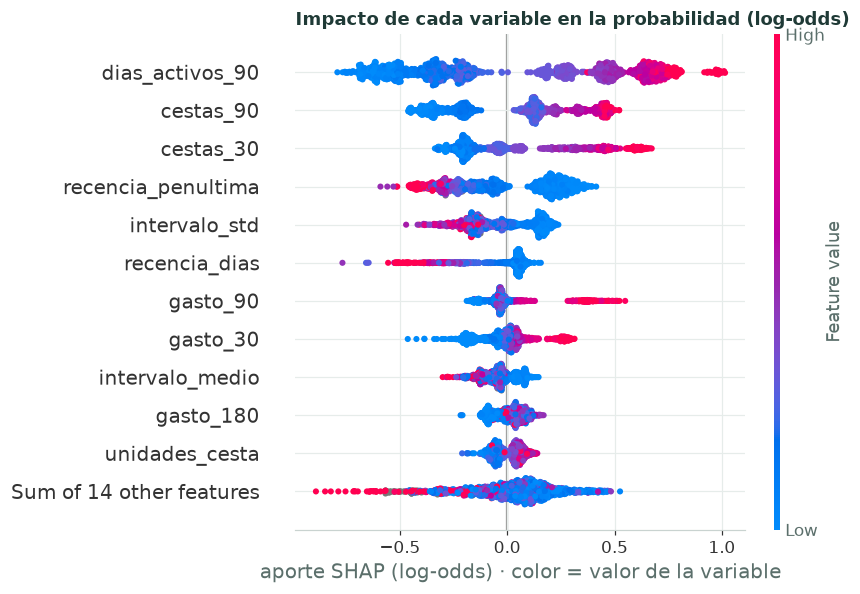

In [12]:
explicador = shap.TreeExplainer(modelo)
muestra = test[X].sample(1500, random_state=0)
valores = explicador(muestra)
plt.figure()
shap.plots.beeswarm(valores, max_display=12, show=False)
plt.title("Impacto de cada variable en la probabilidad (log-odds)")
plt.gca().set_xlabel("aporte SHAP (log-odds) · color = valor de la variable")
plt.gcf().set_size_inches(8, 5.5)
plt.tight_layout()
G.guardar(plt.gcf(), "03_shap_beeswarm")

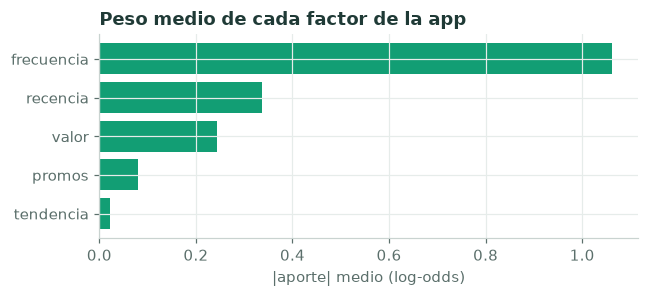

In [13]:
aportes_test, _ = P.aportes_por_grupo(modelo, test[X], platt)
importancia = aportes_test.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(importancia.index, importancia, color=G.MARCA)
ax.set(title="Peso medio de cada factor de la app", xlabel="|aporte| medio (log-odds)")
fig.tight_layout()
G.guardar(fig, "03_factores")

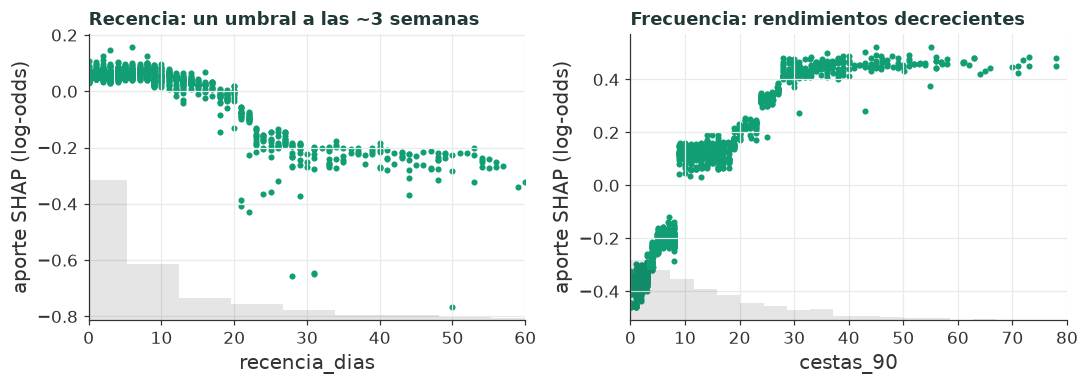

In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
shap.plots.scatter(valores[:, "recencia_dias"], ax=a1, show=False, color=G.MARCA)
a1.set_xlim(0, 60)
a1.set(title="Recencia: un umbral a las ~3 semanas", ylabel="aporte SHAP (log-odds)")
shap.plots.scatter(valores[:, "cestas_90"], ax=a2, show=False, color=G.MARCA)
a2.set_xlim(0, 80)
a2.set(title="Frecuencia: rendimientos decrecientes", ylabel="aporte SHAP (log-odds)")
fig.tight_layout()
G.guardar(fig, "03_dependencia")

- La **frecuencia** es, con diferencia, el factor dominante: el hábito predice el hábito.
- La **recencia** funciona como un umbral: hasta ~20 días sin venir la probabilidad casi no
  cambia; pasadas tres semanas cae de golpe y después se estabiliza (3 o 6 semanas sin comprar
  pesan parecido). Es la clase de no linealidad que la logística no captura sin
  transformaciones a mano.
- Las variables con más peso individual son de **ritmo**: días con compra en los últimos 90
  días y cestas en 30/90 días.
- **Promos** y **tendencia** aportan poco a corto plazo.

### Un cliente, explicado como en la app

In [15]:
i = int(np.argmin(np.abs(p_lgbm - 0.55)))
hogar = test.index[i]
_, intercepto = P.aportes_por_grupo(modelo, test[X].iloc[[i]], platt)
fila = aportes_test.loc[hogar].sort_values(key=np.abs, ascending=False)
print(
    f"Hogar {hogar} · probabilidad {p_lgbm[i]:.0%} · punto de partida (intercepto) {intercepto:+.2f} log-odds"
)
for factor, aporte in fila.items():
    print(f"  {factor:<11} {aporte:+.2f}  {'▲ sube' if aporte > 0 else '▼ baja'}")
print(
    f"  σ({intercepto:+.2f} {fila.sum():+.2f}) = {1 / (1 + np.exp(-(intercepto + fila.sum()))):.0%}"
)

Hogar 1573 · probabilidad 55% · punto de partida (intercepto) +1.49 log-odds
  frecuencia  -0.84  ▼ baja
  valor       -0.45  ▼ baja
  recencia    -0.02  ▼ baja
  tendencia   +0.01  ▲ sube
  promos      +0.01  ▲ sube
  σ(+1.49 -1.29) = 55%


## 7. Modelo final y puntuación al 31-dic

Se reentrena con **todos** los cortes con etiqueta (entrenamiento + validación + test), con
los mismos hiperparámetros y la misma calibración, y se puntúa a cada hogar al 31-dic-2017:
la probabilidad de comprar en las dos primeras semanas de 2018.

,probabilidad
count,"2,469.0000"
mean,0.7084
std,0.2657
min,0.0999
25%,0.5007
50%,0.7921
75%,0.9494
max,0.9944


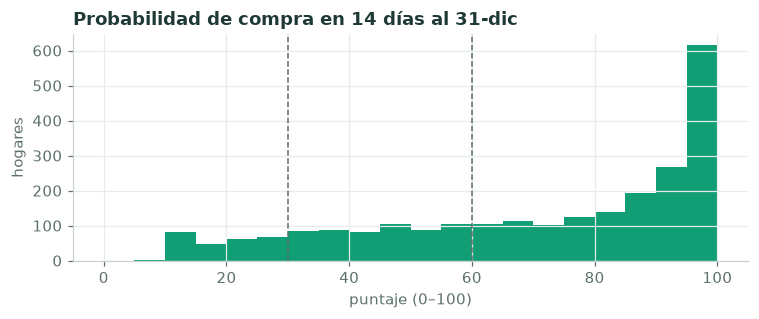

In [16]:
todo = pd.concat([ent, val, test])
final = P.entrenar_lgbm(todo[X], todo["y"], mejores, rondas=rondas)
f_fin = F.features_en(c, P.CORTE_FINAL, camp)
aportes_fin, intercepto_fin = P.aportes_por_grupo(final, f_fin[X], platt)
prob_fin = pd.Series(platt(P.log_odds(final, f_fin[X])), index=f_fin.index, name="probabilidad")

MODELOS.mkdir(parents=True, exist_ok=True)
joblib.dump(
    {"modelo": final, "platt": platt, "features": X, "params": mejores, "rondas": rondas},
    MODELOS / "propension.joblib",
)
pd.concat([prob_fin, aportes_fin], axis=1).assign(intercepto=intercepto_fin).to_parquet(
    PROCESADOS / "propension_fin.parquet"
)

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(prob_fin * 100, bins=20, range=(0, 100), color=G.MARCA)
ax.axvline(30, color=G.TINTA_2, ls="--", lw=1)
ax.axvline(60, color=G.TINTA_2, ls="--", lw=1)
ax.set(
    title="Probabilidad de compra en 14 días al 31-dic", xlabel="puntaje (0–100)", ylabel="hogares"
)
fig.tight_layout()
prob_fin.describe().to_frame()

In [17]:
G.guardar_metricas(
    "propension",
    {
        "ventana_dias": P.VENTANA,
        **{f"lgbm_{k}": v for k, v in tabla.loc["LightGBM + Platt"].items()},
        **{f"logistica_{k}": v for k, v in tabla.loc["Logística"].items()},
        "delta_auc_ic95": [
            round(float(np.percentile(dif, 2.5)), 4),
            round(float(np.percentile(dif, 97.5)), 4),
        ],
        "platt_a": platt.a,
        "platt_b": platt.b,
        "arboles": int(rondas),
    },
)

## Conclusiones

- Pregunta: compra en 14 días (tasa base ≈ 71 %). ROC-AUC en test ≈ 0,87, con buena calibración.
- LightGBM supera a la logística de forma consistente pero modesta; se elige por calibración,
  no linealidades y explicaciones exactas.
- El puntaje se descompone en los cinco factores de la app y la suma cuadra con la
  probabilidad, así que el "por qué" que ve el usuario es fiel al modelo.